# Lab Assignment 10: Multi-Head Attention, Transformer Encoders & Fine-Tuning BERT

**Objective:**
In Lab 8 you built a single attention mechanism inside an LSTM. In Lab 9 you fine-tuned a pre-trained Transformer for translation. In this lab you will **open the black box**: build *scaled dot-product attention* and *multi-head attention* from scratch, assemble them into a mini Transformer encoder, and then compare it with a pre-trained **BERT** model fine-tuned on the same task.

**Task:** Sentiment classification on the **SST-2** dataset (positive / negative movie-review sentences).

**Learning outcomes**
1. Implement scaled dot-product and multi-head attention and verify them against PyTorch.
2. Build a Transformer encoder block (attention + feed-forward + residual + LayerNorm + positional encoding).
3. Understand why BERT (bidirectional, pre-trained encoder) is different from the decoder/LSTM models in previous labs.
4. Fine-tune BERT and evaluate with Accuracy and F1.
5. Visualise and interpret what individual attention heads learn.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 10 |
| 2 | Scaled Dot-Product Attention | 15 |
| 3 | Multi-Head Attention + Encoder Block | 25 |
| 4 | Mini-Transformer trained from scratch | 15 |
| 5 | Fine-tuning BERT | 20 |
| 6 | Attention Head Visualisation | 10 |
| 7 | Comparative Analysis & Reflection | 5 |
| | **Total** | **100** |


## Theory Recap

**Scaled dot-product attention** (Lab 8 used an un-scaled version):

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

* `Q` (queries), `K` (keys), `V` (values) are linear projections of the input.
* Dividing by $\sqrt{d_k}$ stops the dot products from growing large, which would push softmax into regions with tiny gradients.

**Multi-head attention** runs `h` attention operations in parallel, each in a lower-dimensional subspace ($d_k = d_{model}/h$), then concatenates and projects the results:

$$\text{MHA}(X)=\text{Concat}(\text{head}_1,\dots,\text{head}_h)W^O$$

Different heads can specialise (e.g. syntax, neighbouring words, rare-word focus).

**BERT** = a stack of Transformer *encoder* blocks, pre-trained with Masked Language Modelling (MLM) and Next-Sentence Prediction (NSP). The `[CLS]` token's final hidden state is used as the sentence representation for classification.

| Model | Direction | Attention type | Pre-trained? |
|---|---|---|---|
| LSTM + Attention (Lab 8) | Left→right encoder (or BiLSTM) | Cross-attention only | No |
| Marian Transformer (Lab 9) | Encoder-decoder | Self + Cross | Yes |
| **BERT (this lab)** | Encoder only, bidirectional | Self-attention | Yes |


## Part 1: Setup and Data (10 points)

### 1.1 Install & import libraries

In [27]:
!pip install -q transformers datasets evaluate accelerate bertviz scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 21.3 MB/s eta 0:00:00


In [28]:
import os
import math
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    pipeline
)
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu130
Device: cuda


### 1.2 Load SST-2
Use `load_dataset("glue", "sst2")`. To keep training fast on a Colab T4, use a **subset**: 5,000 training samples and the full validation set (872 samples) as your test set.
Print the dataset structure, 3 random examples, and the class distribution.

In [29]:
%pip install -q --upgrade datasets huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


In [30]:
from datasets import load_dataset

raw_datasets = load_dataset("nyu-mll/glue", "sst2")

print(raw_datasets)

train_raw = raw_datasets["train"].shuffle(seed=SEED).select(
    range(min(5000, len(raw_datasets["train"])))
)

test_raw = raw_datasets["validation"]

print("Training samples:", len(train_raw))
print("Test samples:", len(test_raw))

for idx in random.sample(range(len(train_raw)), 3):
    print({
        "sentence": train_raw[idx]["sentence"],
        "label": train_raw[idx]["label"]
    })

labels, counts = np.unique(train_raw["label"], return_counts=True)

print("Training class distribution:")
for label, count in zip(labels, counts):
    name = "Negative" if label == 0 else "Positive"
    print(name, ":", int(count))

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})
Training samples: 5000
Test samples: 872
{'sentence': 'mariah carey gives us another peek at some of the magic we saw in glitter here in wisegirls . ', 'label': 1}
{'sentence': 'does its best ', 'label': 1}
{'sentence': 'lack contrast , are murky and ', 'label': 0}
Training class distribution:
Negative : 2266
Positive : 2734


### 1.3 Tokenize
Load the `bert-base-uncased` tokenizer. Tokenize with `truncation=True`, `max_length=64`, and pad dynamically (use `DataCollatorWithPadding`).
Print one sentence together with its `input_ids`, the decoded tokens (`convert_ids_to_tokens`) and the `attention_mask`. **Explain in a markdown cell:** what are `[CLS]`, `[SEP]` and `##` word-pieces?

In [31]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def tokenize_batch(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=64
    )

train_tokenized = train_raw.map(
    tokenize_batch,
    batched=True,
    remove_columns=["sentence", "idx"]
)

test_tokenized = test_raw.map(
    tokenize_batch,
    batched=True,
    remove_columns=["sentence", "idx"]
)

example_sentence = train_raw[0]["sentence"]
example_enc = tokenizer(
    example_sentence,
    truncation=True,
    max_length=64
)

print("Sentence:", example_sentence)
print("input_ids:", example_enc["input_ids"])
print("Tokens:", tokenizer.convert_ids_to_tokens(example_enc["input_ids"]))
print("attention_mask:", example_enc["attention_mask"])

Sentence: klein , charming in comedies like american pie and dead-on in election , 
input_ids: [101, 12555, 1010, 11951, 1999, 22092, 2066, 2137, 11345, 1998, 2757, 1011, 2006, 1999, 2602, 1010, 102]
Tokens: ['[CLS]', 'klein', ',', 'charming', 'in', 'comedies', 'like', 'american', 'pie', 'and', 'dead', '-', 'on', 'in', 'election', ',', '[SEP]']
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


**Tokenization explanation**

- `[CLS]` is the special token placed at the beginning of the input. Its final representation is commonly used for classification.
- `[SEP]` marks the end of a sentence or separates two text segments.
- `##` indicates a continuation of a word split into smaller WordPiece tokens.
- The attention mask is 1 for real tokens and 0 for padding.

## Part 2: Scaled Dot-Product Attention from Scratch (15 points)

### 2.1 Implement the function
Write `scaled_dot_product_attention(Q, K, V, mask=None)` that returns `(output, attention_weights)`.

Requirements:
* Input shapes: `(batch, heads, seq_len, d_k)`
* Scale by `sqrt(d_k)`
* If `mask` is given (1 = keep, 0 = padding), set masked scores to a very large negative number **before** softmax
* Do **not** use `nn.MultiheadAttention` or `F.scaled_dot_product_attention` in your implementation

In [32]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)

    scores = torch.matmul(Q, K.transpose(-2, -1))
    scores = scores / math.sqrt(d_k)

    if mask is not None:
        mask = mask.to(device=scores.device, dtype=torch.bool)
        scores = scores.masked_fill(~mask, -1e9)

    attention_weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(attention_weights, V)

    return output, attention_weights

### 2.2 Verify
Create random `Q, K, V` and compare your output with `torch.nn.functional.scaled_dot_product_attention` using `torch.allclose`. Also check that every row of the weights sums to 1 and that padded positions receive ~0 weight.

In [33]:
torch.manual_seed(SEED)

B, H, T, DK = 2, 3, 5, 8

Q = torch.randn(B, H, T, DK)
K = torch.randn(B, H, T, DK)
V = torch.randn(B, H, T, DK)

keep = torch.tensor([
    [1, 1, 1, 0, 0],
    [1, 1, 1, 1, 0]
])

mask = keep[:, None, None, :]

out, weights = scaled_dot_product_attention(Q, K, V, mask)

reference = torch.nn.functional.scaled_dot_product_attention(
    Q, K, V, attn_mask=mask.bool()
)

print("Matches PyTorch:", torch.allclose(out, reference, atol=1e-6))
print("Maximum difference:", (out - reference).abs().max().item())

print(
    "Rows sum to 1:",
    torch.allclose(
        weights.sum(dim=-1),
        torch.ones_like(weights.sum(dim=-1)),
        atol=1e-6
    )
)

masked_weights = weights.masked_select(
    (~mask.bool()).expand_as(weights)
)

print("Maximum masked weight:", masked_weights.abs().max().item())

Matches PyTorch: True
Maximum difference: 5.960464477539062e-07
Rows sum to 1: True
Maximum masked weight: 0.0


### 2.3 Short question
Compare this with the attention you wrote in **Lab 8** (Bahdanau / dot-product). In 3-4 lines: what is the difference between *additive* and *scaled dot-product* attention, and why does the scaling factor matter? *(Hint: try d_k = 512 with and without scaling and print the std of the scores and the max softmax weight.)*

In [34]:
torch.manual_seed(SEED)

d_k = 512

q = torch.randn(32, d_k)
k = torch.randn(32, d_k)

raw_scores = q @ k.T
scaled_scores = raw_scores / math.sqrt(d_k)

raw_max = torch.softmax(
    raw_scores, dim=-1
).max(dim=-1).values.mean().item()

scaled_max = torch.softmax(
    scaled_scores, dim=-1
).max(dim=-1).values.mean().item()

print("d_k =", d_k)
print(
    "Unscaled score std:",
    round(raw_scores.std().item(), 3),
    "| Mean max-softmax weight:",
    round(raw_max, 4)
)

print(
    "Scaled score std:",
    round(scaled_scores.std().item(), 3),
    "| Mean max-softmax weight:",
    round(scaled_max, 4)
)

d_k = 512
Unscaled score std: 22.353 | Mean max-softmax weight: 0.938
Scaled score std: 0.988 | Mean max-softmax weight: 0.1551


**Answer — Additive vs. scaled dot-product attention**

Bahdanau/additive attention uses a learned feed-forward scoring function to combine the query and key. Dot-product attention uses their inner product, and scaled dot-product attention divides this score by `sqrt(d_k)`. Scaling prevents scores from becoming too large as the feature dimension increases. This avoids overly peaked softmax probabilities and helps gradients remain useful during training.

## Part 3: Multi-Head Attention and the Transformer Encoder Block (25 points)

### 3.1 MultiHeadAttention layer
Implement `class MultiHeadAttention(nn.Module)` with:
* `__init__(self, d_model, num_heads)` — assert `d_model % num_heads == 0`; create `W_q, W_k, W_v, W_o` as `nn.Linear`
* `split_heads(x)` : `(B, T, d_model) -> (B, h, T, d_k)`
* `forward(x, mask=None)` : project → split → attention (your function from Part 2) → merge heads → `W_o`
* store the last attention weights in `self.attn_weights` for visualisation later

In [35]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attn_weights = None

    def split_heads(self, x):
        B, T, _ = x.shape

        return x.reshape(
            B, T, self.num_heads, self.d_k
        ).transpose(1, 2)

    def forward(self, x, mask=None):
        q = self.split_heads(self.W_q(x))
        k = self.split_heads(self.W_k(x))
        v = self.split_heads(self.W_v(x))

        attended, self.attn_weights = scaled_dot_product_attention(
            q, k, v, mask
        )

        merged = attended.transpose(1, 2).contiguous().reshape(
            x.size(0), x.size(1), self.d_model
        )

        return self.W_o(merged)

### 3.2 Sanity check
Copy the weights of your layer into `nn.MultiheadAttention(d_model, num_heads, batch_first=True)` (hint: its `in_proj_weight` stacks Q, K, V) and confirm the outputs match (`atol=1e-5`).

In [36]:
torch.manual_seed(SEED)

d_model, num_heads = 16, 4

custom = MultiHeadAttention(d_model, num_heads).eval()

torch_mha = nn.MultiheadAttention(
    d_model,
    num_heads,
    batch_first=True,
    dropout=0.0
).eval()

with torch.no_grad():
    torch_mha.in_proj_weight.copy_(
        torch.cat([
            custom.W_q.weight,
            custom.W_k.weight,
            custom.W_v.weight
        ], dim=0)
    )

    torch_mha.in_proj_bias.copy_(
        torch.cat([
            custom.W_q.bias,
            custom.W_k.bias,
            custom.W_v.bias
        ], dim=0)
    )

    torch_mha.out_proj.weight.copy_(custom.W_o.weight)
    torch_mha.out_proj.bias.copy_(custom.W_o.bias)

    x_check = torch.randn(2, 6, d_model)

    custom_out = custom(x_check)

    builtin_out, _ = torch_mha(
        x_check, x_check, x_check,
        need_weights=False
    )

print(
    "Custom and PyTorch outputs match:",
    torch.allclose(custom_out, builtin_out, atol=1e-5)
)

print(
    "Maximum difference:",
    (custom_out - builtin_out).abs().max().item()
)

Custom and PyTorch outputs match: True
Maximum difference: 0.0


### 3.3 Positional Encoding
Attention has no notion of order. Implement sinusoidal positional encoding and plot it as a heatmap (positions × dimensions).

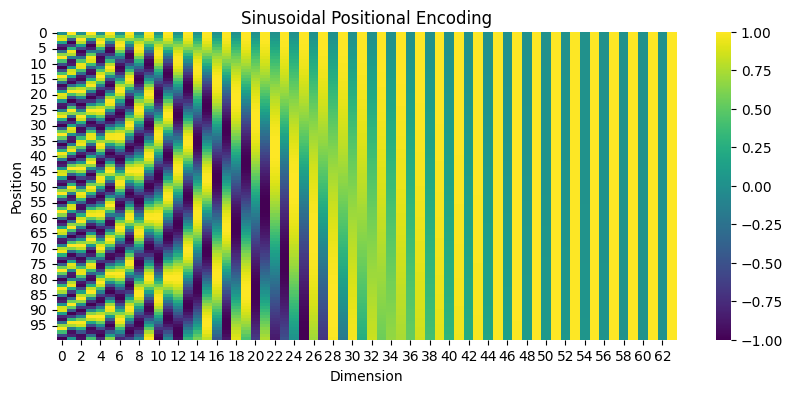

In [37]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()

        position = torch.arange(
            max_len, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)

        pe[:, 0::2] = torch.sin(position * div_term)

        pe[:, 1::2] = torch.cos(
            position * div_term[:pe[:, 1::2].shape[1]]
        )

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)].to(dtype=x.dtype)


pe_demo = PositionalEncoding(d_model=64, max_len=100)

plt.figure(figsize=(10, 4))
sns.heatmap(pe_demo.pe[0].cpu().numpy(), cmap="viridis")
plt.xlabel("Dimension")
plt.ylabel("Position")
plt.title("Sinusoidal Positional Encoding")
plt.show()

### 3.4 Transformer Encoder Block
Implement `EncoderBlock(d_model, num_heads, d_ff, dropout)`:

`x → MHA → Dropout → Add & LayerNorm → FeedForward (Linear-GELU-Linear) → Dropout → Add & LayerNorm`

Then answer in markdown: **Why are residual connections and LayerNorm needed in deep Transformers?**

In [38]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        self.attention = MultiHeadAttention(d_model, num_heads)

        self.dropout1 = nn.Dropout(dropout)
        self.norm1 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )

        self.dropout2 = nn.Dropout(dropout)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        attention_output = self.attention(x, mask)
        x = self.norm1(x + self.dropout1(attention_output))

        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_output))

        return x


block_demo = EncoderBlock(64, 4, 128)

demo_out = block_demo(
    torch.randn(2, 7, 64),
    torch.ones(2, 1, 1, 7)
)

print("Encoder block output shape:", tuple(demo_out.shape))

Encoder block output shape: (2, 7, 64)


**Why are residual connections and LayerNorm needed?**

Residual connections preserve the input signal and provide a direct path for gradients, making deep networks easier to train. LayerNorm stabilises the feature values for each token and helps training converge more reliably.

## Part 4: Mini-Transformer Classifier Trained from Scratch (15 points)

### 4.1 Build the model
Create `MiniTransformerClassifier` using: token embedding (use the BERT tokenizer's vocab size) → positional encoding → **2** `EncoderBlock`s (`d_model=128`, `heads=4`, `d_ff=256`) → mean-pool over non-padding tokens → `Linear(d_model, 2)`.
Print the number of trainable parameters.

In [39]:
class MiniTransformerClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        pad_token_id,
        d_model=128,
        num_heads=4,
        d_ff=256,
        num_layers=2,
        max_len=64,
        dropout=0.1
    ):
        super().__init__()

        self.pad_token_id = pad_token_id

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_token_id
        )

        self.position = PositionalEncoding(
            d_model,
            max_len=max_len
        )

        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(d_model, 2)

    def forward(self, input_ids, attention_mask):
        x = self.embedding(input_ids)
        x = self.position(x)

        pad_mask = attention_mask[:, None, None, :].bool()

        for block in self.blocks:
            x = block(x, pad_mask)

        valid = attention_mask.unsqueeze(-1).to(x.dtype)

        pooled = (x * valid).sum(dim=1) / valid.sum(
            dim=1
        ).clamp(min=1.0)

        return self.classifier(pooled)


mini_model = MiniTransformerClassifier(
    len(tokenizer),
    tokenizer.pad_token_id
).to(device)

mini_params = sum(
    p.numel()
    for p in mini_model.parameters()
    if p.requires_grad
)

print(f"Mini-Transformer trainable parameters: {mini_params:,}")

Mini-Transformer trainable parameters: 4,172,034


### 4.2 Train
Write a standard PyTorch training loop (AdamW, lr=1e-3, 5 epochs, batch size 32). Log train loss and validation accuracy per epoch and plot both curves.
Note the padding mask must be built from `attention_mask` and reshaped to `(B, 1, 1, T)`.

Epoch 1/5 | train loss=0.6655 | validation accuracy=0.6411
Epoch 2/5 | train loss=0.5618 | validation accuracy=0.6709
Epoch 3/5 | train loss=0.4294 | validation accuracy=0.7099
Epoch 4/5 | train loss=0.2929 | validation accuracy=0.7018
Epoch 5/5 | train loss=0.1934 | validation accuracy=0.7213
Mini-Transformer training time: 0.39 minutes


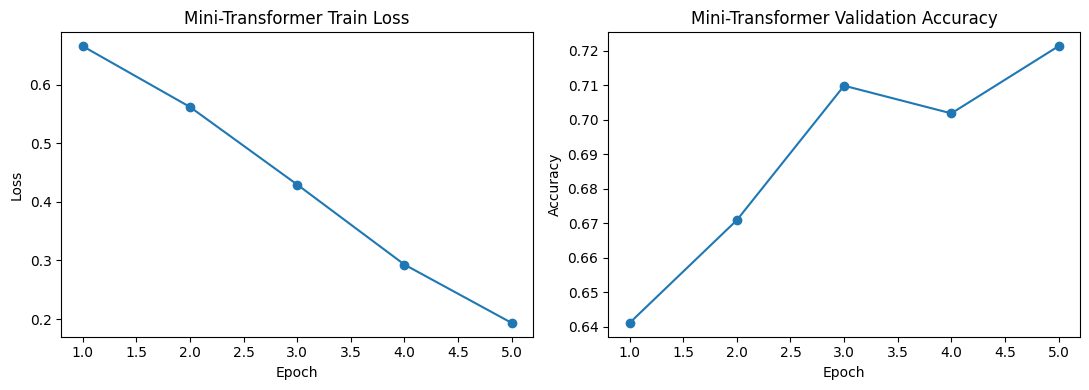

In [40]:
class SST2TorchDataset(Dataset):
    def __init__(self, hf_dataset):
        self.dataset = hf_dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        item = self.dataset[index]

        return {
            "input_ids": item["input_ids"],
            "attention_mask": item["attention_mask"],
            "labels": item["label"]
        }


def torch_collate(features):
    batch = data_collator([
        {
            "input_ids": f["input_ids"],
            "attention_mask": f["attention_mask"]
        }
        for f in features
    ])

    batch["labels"] = torch.tensor(
        [f["labels"] for f in features],
        dtype=torch.long
    )

    return batch


train_loader = DataLoader(
    SST2TorchDataset(train_tokenized),
    batch_size=32,
    shuffle=True,
    collate_fn=torch_collate
)

test_loader = DataLoader(
    SST2TorchDataset(test_tokenized),
    batch_size=32,
    shuffle=False,
    collate_fn=torch_collate
)

optimizer = torch.optim.AdamW(
    mini_model.parameters(),
    lr=1e-3
)

criterion = nn.CrossEntropyLoss()

mini_history = {
    "train_loss": [],
    "val_accuracy": []
}

mini_start = time.time()

for epoch in range(5):
    mini_model.train()

    running_loss = 0.0
    seen = 0

    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = mini_model(input_ids, attention_mask)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mini_model.parameters(), 1.0
        )

        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        seen += labels.size(0)

    epoch_loss = running_loss / seen

    mini_model.eval()
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for batch in test_loader:
            logits = mini_model(
                batch["input_ids"].to(device),
                batch["attention_mask"].to(device)
            )

            val_preds.extend(
                logits.argmax(dim=-1).cpu().tolist()
            )

            val_labels.extend(batch["labels"].tolist())

    val_acc = accuracy_score(val_labels, val_preds)

    mini_history["train_loss"].append(epoch_loss)
    mini_history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"train loss={epoch_loss:.4f} | "
        f"validation accuracy={val_acc:.4f}"
    )

mini_train_time = time.time() - mini_start

print(
    f"Mini-Transformer training time: "
    f"{mini_train_time / 60:.2f} minutes"
)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(
    range(1, 6),
    mini_history["train_loss"],
    marker="o"
)
ax[0].set(
    title="Mini-Transformer Train Loss",
    xlabel="Epoch",
    ylabel="Loss"
)

ax[1].plot(
    range(1, 6),
    mini_history["val_accuracy"],
    marker="o"
)
ax[1].set(
    title="Mini-Transformer Validation Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy"
)

plt.tight_layout()
plt.show()

### 4.3 Evaluate
Report accuracy, F1 and the confusion matrix on the test set. Record the **total training time**.

In [41]:
mini_model.eval()

mini_preds = []
mini_labels = []

with torch.no_grad():
    for batch in test_loader:
        logits = mini_model(
            batch["input_ids"].to(device),
            batch["attention_mask"].to(device)
        )

        mini_preds.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

        mini_labels.extend(batch["labels"].tolist())

mini_accuracy = accuracy_score(mini_labels, mini_preds)

mini_f1 = f1_score(
    mini_labels,
    mini_preds,
    zero_division=0
)

mini_cm = confusion_matrix(mini_labels, mini_preds)

print(f"Mini-Transformer test accuracy: {mini_accuracy:.4f}")
print(f"Mini-Transformer test F1: {mini_f1:.4f}")

print(
    "Confusion matrix "
    "(rows=true, columns=predicted; labels 0, 1):\n",
    mini_cm
)

print(
    "Total mini-Transformer training time (seconds):",
    round(mini_train_time, 2)
)

Mini-Transformer test accuracy: 0.7213
Mini-Transformer test F1: 0.7303
Confusion matrix (rows=true, columns=predicted; labels 0, 1):
 [[300 128]
 [115 329]]
Total mini-Transformer training time (seconds): 23.48


## Part 5: Fine-Tuning BERT (20 points)

### 5.1 Load the pre-trained model
Load `AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)`. Print the parameter count and compare it with your mini-Transformer.

In [42]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

bert_total_params = sum(
    p.numel() for p in bert_model.parameters()
)

bert_trainable_params = sum(
    p.numel() for p in bert_model.parameters()
    if p.requires_grad
)

print(f"BERT total parameters: {bert_total_params:,}")
print(f"BERT trainable parameters: {bert_trainable_params:,}")
print(f"Mini-Transformer parameters: {mini_params:,}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT total parameters: 109,483,778
BERT trainable parameters: 109,483,778
Mini-Transformer parameters: 4,172,034


### 5.2 Metrics
Define `compute_metrics` that returns **accuracy** and **F1** (use `evaluate` or `sklearn`).

In [43]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, zero_division=0)
    }

### 5.3 Configure and run training
Use `TrainingArguments`: `learning_rate=2e-5`, `num_train_epochs=3`, `per_device_train_batch_size=32`, `weight_decay=0.01`, `eval_strategy="epoch"`, `fp16=True` (GPU), `report_to="none"`. Train with `Trainer` and record training time.

In [44]:
def make_training_args(
    output_dir,
    learning_rate=2e-5,
    epochs=3
):
    return TrainingArguments(
        output_dir=output_dir,
        learning_rate=learning_rate,
        num_train_epochs=epochs,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=32,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="no",
        logging_strategy="epoch",
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED,
        data_seed=SEED
    )


bert_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

bert_trainer = Trainer(
    model=bert_model,
    args=make_training_args(
        "./bert_full_sst2",
        learning_rate=2e-5,
        epochs=3
    ),
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

bert_start = time.time()

bert_trainer.train()

bert_train_time = time.time() - bert_start

bert_eval = bert_trainer.evaluate(test_tokenized)

bert_accuracy = float(bert_eval["eval_accuracy"])
bert_f1 = float(bert_eval["eval_f1"])

bert_total_params = sum(
    p.numel() for p in bert_model.parameters()
)

print(
    "Full fine-tuned BERT results:",
    {
        "accuracy": bert_accuracy,
        "f1": bert_f1,
        "seconds": round(bert_train_time, 2)
    }
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.396007,0.262740,0.888761,0.890147
2,0.186004,0.265357,0.899083,0.900452
3,0.105931,0.347835,0.891055,0.895028


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.105931,0.347835,3,0.891055,0.895028


Full fine-tuned BERT results: {'accuracy': 0.8910550458715596, 'f1': 0.8950276243093923, 'seconds': 54.66}


### 5.4 Ablation: frozen vs. full fine-tuning
Re-load a fresh BERT and **freeze all encoder layers** (`for p in model.bert.parameters(): p.requires_grad = False`) so only the classifier head trains. Train with the same settings (you may use lr=1e-3).
Report a table with *trainable parameters*, *accuracy*, *F1*, and *training time* for: frozen BERT vs. fully fine-tuned BERT.

In [45]:
frozen_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

for p in frozen_model.bert.parameters():
    p.requires_grad = False

frozen_model.to(device)

frozen_trainable_params = sum(
    p.numel()
    for p in frozen_model.parameters()
    if p.requires_grad
)

frozen_total_params = sum(
    p.numel() for p in frozen_model.parameters()
)

print(f"Frozen BERT total parameters: {frozen_total_params:,}")
print(f"Frozen BERT trainable parameters: {frozen_trainable_params:,}")

frozen_trainer = Trainer(
    model=frozen_model,
    args=make_training_args(
        "./bert_frozen_sst2",
        learning_rate=1e-3,
        epochs=3
    ),
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

frozen_start = time.time()

frozen_trainer.train()

frozen_train_time = time.time() - frozen_start

frozen_eval = frozen_trainer.evaluate(test_tokenized)

frozen_accuracy = float(frozen_eval["eval_accuracy"])
frozen_f1 = float(frozen_eval["eval_f1"])

print(
    "Frozen BERT results:",
    {
        "accuracy": frozen_accuracy,
        "f1": frozen_f1,
        "seconds": round(frozen_train_time, 2)
    }
)

import pandas as pd

ablation_results = pd.DataFrame([
    {
        "Model": "BERT (frozen, head only)",
        "Trainable parameters": frozen_trainable_params,
        "Accuracy": frozen_accuracy,
        "F1": frozen_f1,
        "Training time (s)": round(frozen_train_time, 2)
    },
    {
        "Model": "BERT (full fine-tuning)",
        "Trainable parameters": bert_trainable_params,
        "Accuracy": bert_accuracy,
        "F1": bert_f1,
        "Training time (s)": round(bert_train_time, 2)
    }
])

display(ablation_results)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Frozen BERT total parameters: 109,483,778
Frozen BERT trainable parameters: 1,538


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.657768,0.616941,0.720183,0.727069
2,0.620940,0.598863,0.673165,0.745763
3,0.598546,0.585787,0.696101,0.751640


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.598546,0.585787,3,0.696101,0.751640


Frozen BERT results: {'accuracy': 0.6961009174311926, 'f1': 0.7516401124648547, 'seconds': 14.48}


,Model,Trainable parameters,Accuracy,F1,Training time (s)
0,"BERT (frozen, head only)",1538,0.696101,0.751640,14.48
1,BERT (full fine-tuning),109483778,0.891055,0.895028,54.66


### 5.5 Inference
Use `pipeline("text-classification", model=..., tokenizer=...)` to classify these sentences, and add **3 of your own** (include one sarcastic and one negated sentence):
```python
tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
]
```

In [46]:
tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
    "Wow, what a brilliant movie... if your goal is to fall asleep.",
    "I do not think this was a terrible film.",
    "The story felt fresh and the performances were convincing."
]

bert_model.eval()

sentiment_pipe = pipeline(
    "text-classification",
    model=bert_model,
    tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1
)

predictions = sentiment_pipe(
    tests,
    truncation=True,
    max_length=64
)

for sentence, prediction in zip(tests, predictions):
    print(
        f"{prediction['label']:>10s} "
        f"({prediction['score']:.3f}) | {sentence}"
    )

   LABEL_1 (0.997) | This movie was an absolute masterpiece.
   LABEL_0 (0.989) | I wasted two hours of my life on this film.
   LABEL_1 (0.961) | The acting was not bad at all.
   LABEL_1 (0.996) | The plot was predictable, but the visuals were stunning.
   LABEL_1 (0.996) | Wow, what a brilliant movie... if your goal is to fall asleep.
   LABEL_1 (0.876) | I do not think this was a terrible film.
   LABEL_1 (0.997) | The story felt fresh and the performances were convincing.


## Part 6: Visualising Attention Heads (10 points)

### 6.1 Extract attentions
Load your fine-tuned BERT with `output_attentions=True` and run one sentence. `outputs.attentions` is a tuple of 12 tensors with shape `(1, 12, T, T)` — one per layer.

In [47]:
attention_sentence = (
    "The movie was not good, but the ending was surprisingly moving."
)

attention_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2,
    attn_implementation="eager"
)

attention_model.load_state_dict(bert_model.state_dict())
attention_model.to(device).eval()

attention_inputs = tokenizer(
    attention_sentence,
    return_tensors="pt",
    truncation=True,
    max_length=64
).to(device)

with torch.no_grad():
    attention_outputs = attention_model(
        **attention_inputs,
        output_attentions=True,
        return_dict=True
    )

attentions = attention_outputs.attentions

attention_tokens = tokenizer.convert_ids_to_tokens(
    attention_inputs["input_ids"][0].cpu().tolist()
)

print("Tokens:", attention_tokens)
print("Number of layers:", len(attentions))
print("Attention tensor shape:", tuple(attentions[0].shape))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', ',', 'but', 'the', 'ending', 'was', 'surprisingly', 'moving', '.', '[SEP]']
Number of layers: 12
Attention tensor shape: (1, 12, 15, 15)


### 6.2 Heatmaps
Plot a **grid of 4 heads** (e.g. layer 1 vs layer 12, two heads each) as heatmaps with tokens on the axes. Then use `bertviz` (`head_view` or `model_view`) to produce an interactive view.

> In Colab the `bertviz` call must be the last line of the cell.

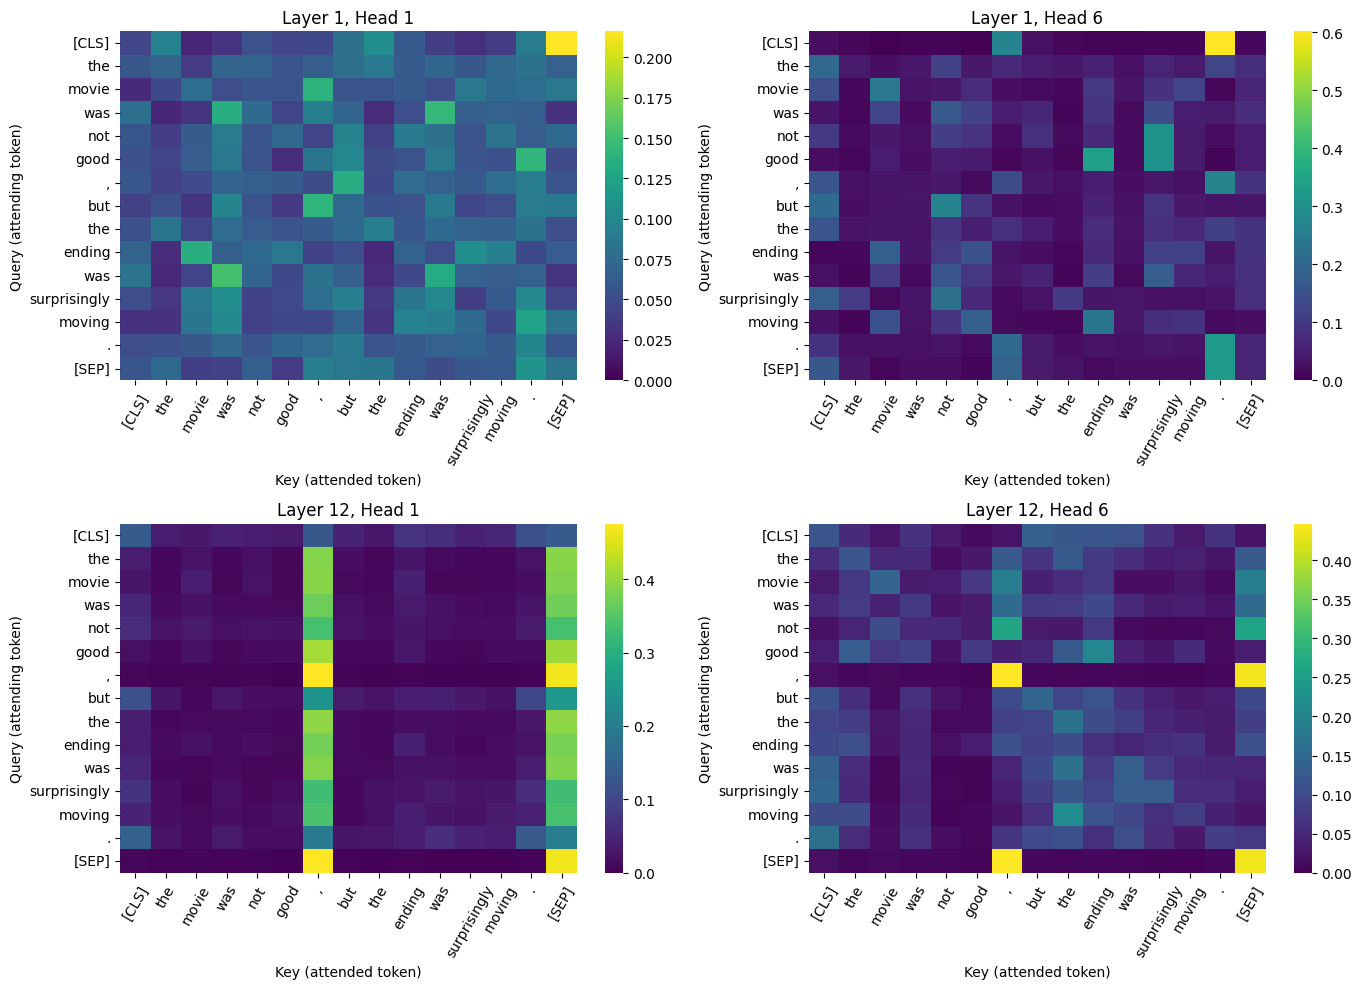

<IPython.core.display.Javascript object>

In [48]:
selected_heads = [
    (0, 0),
    (0, 5),
    (11, 0),
    (11, 5)
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (layer_idx, head_idx) in zip(
    axes.flat,
    selected_heads
):
    matrix = (
        attentions[layer_idx][0, head_idx]
        .detach()
        .cpu()
        .numpy()
    )

    sns.heatmap(
        matrix,
        xticklabels=attention_tokens,
        yticklabels=attention_tokens,
        cmap="viridis",
        vmin=0,
        vmax=max(0.01, float(matrix.max())),
        ax=ax
    )

    ax.set_title(
        f"Layer {layer_idx + 1}, Head {head_idx + 1}"
    )
    ax.set_xlabel("Key (attended token)")
    ax.set_ylabel("Query (attending token)")
    ax.tick_params(axis="x", rotation=60)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

try:
    from bertviz import head_view

    tokens_for_viz = tokenizer.convert_ids_to_tokens(
        attention_inputs["input_ids"][0].cpu().tolist()
    )

    head_view(attentions, tokens_for_viz)

except Exception as exc:
    print("Interactive BertViz view unavailable:", repr(exc))

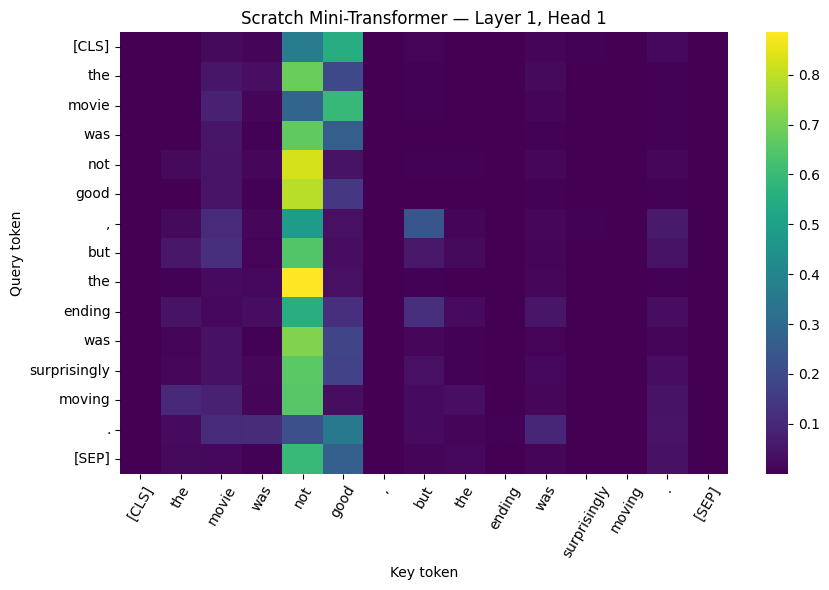

In [49]:
mini_enc = tokenizer(
    attention_sentence,
    return_tensors="pt",
    truncation=True,
    max_length=64
)

mini_inputs = {
    k: v.to(device)
    for k, v in mini_enc.items()
    if k in ("input_ids", "attention_mask")
}

mini_model.eval()

with torch.no_grad():
    _ = mini_model(
        mini_inputs["input_ids"],
        mini_inputs["attention_mask"]
    )

mini_tokens = tokenizer.convert_ids_to_tokens(
    mini_enc["input_ids"][0]
)

mini_attn = (
    mini_model.blocks[0]
    .attention.attn_weights[0, 0]
    .detach()
    .cpu()
    .numpy()
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    mini_attn,
    xticklabels=mini_tokens,
    yticklabels=mini_tokens,
    cmap="viridis"
)

plt.title("Scratch Mini-Transformer — Layer 1, Head 1")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.xticks(rotation=60)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.3 Interpretation of Attention Patterns

**1. Do you find a head that mostly attends to the next/previous token or to `[SEP]` or `[CLS]`?**

In Layer 12, Head 1, many tokens give strong attention to punctuation and `[SEP]`. Some heads in the first layer distribute attention more broadly across the sentence. These patterns show that different heads focus on different token relationships.

**2. How do attention patterns differ between early and late layers?**

The first-layer heatmaps show more distributed attention across tokens. In the final layer, some heads concentrate strongly on particular tokens, such as punctuation and `[SEP]`. This suggests that attention patterns can become more selective in later layers, although this behaviour varies between heads.

**3. Compare BERT with the from-scratch model. Are the attention patterns equally structured? Why?**

The scratch mini-Transformer's first head strongly focuses on the token `not`, while several other tokens also attend to it. BERT shows different patterns across its heads, including strong attention to punctuation and `[SEP]`. BERT's pre-training helps it learn useful language representations, whereas the scratch model has learned only from the small labelled dataset. Attention patterns alone, however, do not prove what a head has learned.


## Part 7: Comparative Analysis & Reflection (5 points)

Fill in the table with your measured results.

| Model | Params | Pre-trained | Test Acc | Test F1 | Train time |
|---|---|---|---|---|---|
| Mini-Transformer (scratch) | ... | No | ... | ... | ... |
| BERT (frozen, head only) | ... | Yes | ... | ... | ... |
| BERT (full fine-tune) | ... | Yes | ... | ... | ... |

**Answer briefly (3–5 lines each):**
1. Why does BERT outperform the same-architecture model trained from scratch, even though both use self-attention?
2. BERT is *encoder-only* and bidirectional, while the Lab 9 Marian model is *encoder-decoder*. Why is BERT unsuitable for generating translations directly?
3. What is the purpose of multiple heads rather than one big head? Give evidence from Part 6.
4. Compare the three paradigms from Labs 8, 9 and 10: *LSTM + attention*, *pre-trained seq2seq Transformer*, *pre-trained encoder (BERT)*. When would you use each?


In [50]:
comparison_results = pd.DataFrame([
    {
        "Model": "Mini-Transformer (scratch)",
        "Params": mini_params,
        "Pre-trained": "No",
        "Test Acc": mini_accuracy,
        "Test F1": mini_f1,
        "Train time (s)": round(mini_train_time, 2)
    },
    {
        "Model": "BERT (frozen, head only)",
        "Params": frozen_total_params,
        "Pre-trained": "Yes",
        "Test Acc": frozen_accuracy,
        "Test F1": frozen_f1,
        "Train time (s)": round(frozen_train_time, 2)
    },
    {
        "Model": "BERT (full fine-tune)",
        "Params": bert_total_params,
        "Pre-trained": "Yes",
        "Test Acc": bert_accuracy,
        "Test F1": bert_f1,
        "Train time (s)": round(bert_train_time, 2)
    }
])

display(comparison_results)

,Model,Params,Pre-trained,Test Acc,Test F1,Train time (s)
0,Mini-Transformer (scratch),4172034,No,0.721330,0.730300,23.48
1,"BERT (frozen, head only)",109483778,Yes,0.696101,0.751640,14.48
2,BERT (full fine-tune),109483778,Yes,0.891055,0.895028,54.66


### Reflection answers

**1. Why can BERT outperform the scratch model?**

Both models use self-attention, but BERT has already learned useful language representations from a very large text corpus. The scratch model must learn grammatical and semantic patterns using only 5,000 labelled examples and five epochs.

**2. Why is BERT not a direct translation generator?**

BERT is an encoder-only model designed to learn bidirectional representations. It does not have an autoregressive decoder for generating a target-language sequence step by step. Marian is an encoder-decoder model designed for translation.

**3. Why use multiple attention heads?**

Each head projects tokens into a different representation subspace and can learn different relationships between tokens. The heatmaps help us inspect these patterns, but they do not prove that every head has one fixed linguistic role.

**4. When should each model be used?**

LSTM with attention is useful for learning sequential encoder-decoder concepts and handling smaller sequence tasks. A pre-trained encoder-decoder Transformer such as Marian is suitable for translation and text generation. BERT is useful for understanding tasks such as sentiment classification, sentence classification, and token classification.

## What to Submit
* The completed notebook with all outputs visible.
* The comparison table from Part 7 and your written answers.
* Screenshots (or outputs) of the attention heatmaps from Part 6.

**Bonus (+5):** Fine-tune a smaller model (`distilbert-base-uncased`) and add it to the table, commenting on the speed/accuracy trade-off.